# Linear Regression - Predicting Fish Weight (Fish Market Dataset)

This notebook demonstrates the development of a **Linear Regression** model to predict fish weight based on physical characteristics (length, height, width, and species).

## 1. Importing Libraries and Dependencies
In this cell, we import all the necessary tools for data manipulation, preprocessing (scaling and encoding categorical variables), modeling, and evaluation.

In [7]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

regressor = LinearRegression()

## 2. Loading and Exploring the Dataset
Here we load the fish market dataset (`fish_market.csv`) and check for any missing values that might require handling.

In [8]:
dataset = pd.read_csv('datasets/fish_market.csv')
dataset.isnull().sum()

Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64


## 3. Data Preprocessing and Train/Test Split
Definition of the feature engineering function (`train_test_features`). This function separates the predictors and target variable, splits the dataset into training and testing sets, standardizes the numerical columns using `StandardScaler`, and applies One-Hot Encoding to the categorical species column (`Species`).


In [9]:
def train_test_features(dataset):
  X = dataset.drop(columns='Weight')
  y = dataset['Weight']
  X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)
  
  # Separa automaticamente o nome da coluna categórica e das numéricas
  cat_cols = ['Species']
  num_cols = [col for col in X.columns if col not in cat_cols]

  transformer = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols), 
        ('cat', OneHotEncoder(), cat_cols)             
    ]
  )

  X_train = transformer.fit_transform(X_train)
  X_test = transformer.transform(X_test)

  return X_train, X_test, y_train, y_test

## 4. Visualization and Evaluation Metrics
Implementation of the `show_grafic_metrics` function to generate plots that help evaluate model performance through residual analysis and actual vs. predicted value comparisons.

In [10]:
def show_grafic_metrics(y_test, y_pred):
  # Configurando o estilo dos gráficos
  sns.set_theme(style="whitegrid")
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

  # 1. Gráfico de Dispersão: Valores Reais vs. Preditos
  ax1.scatter(y_test, y_pred, color='blue', alpha=0.7, edgecolors='k', s=80)
  # Linha de referência (Predição Perfeita)
  lims = [min(min(y_test), min(y_pred)), max(max(y_test), max(y_pred))]
  ax1.plot(lims, lims, color='red', linestyle='--', lw=2, label='Predição Perfeita')
  ax1.set_xlabel('Valores Reais', fontsize=12)
  ax1.set_ylabel('Valores Preditos)', fontsize=12)
  ax1.set_title('Valores Reais vs. Valores Preditos', fontsize=14)
  ax1.legend()

  # 2. Gráfico de Resíduos (Erros)
  residuals = y_test - y_pred
  ax2.scatter(y_pred, residuals, color='purple', alpha=0.7, edgecolors='k', s=80)
  ax2.axhline(y=0, color='red', linestyle='--', lw=2)
  ax2.set_xlabel('Valores Preditos', fontsize=12)
  ax2.set_ylabel('Resíduos (Erros)', fontsize=12)
  ax2.set_title('Gráfico de Resíduos (Análise de Erro)', fontsize=14)

  plt.tight_layout()
  plt.show()

  print('\n RESULTADOS TREINAMENTO')
  print(f'MAE (Erro Médio Absoluto): {mean_absolute_error(y_test, y_pred)}')
  print(f'MSE (Erro Quadrático Médio): {mean_squared_error(y_test, y_pred)}')
  print(f'RMSE (Raiz do Erro Quadrático): {root_mean_squared_error(y_test, y_pred)}')
  print(f'R2_SCORE (Coeficiente R²): {r2_score(y_test, y_pred)}')


## 5. Model Training and Evaluation
We preprocess the data, train the linear regression model, and display the numerical results accompanied by visual analysis.

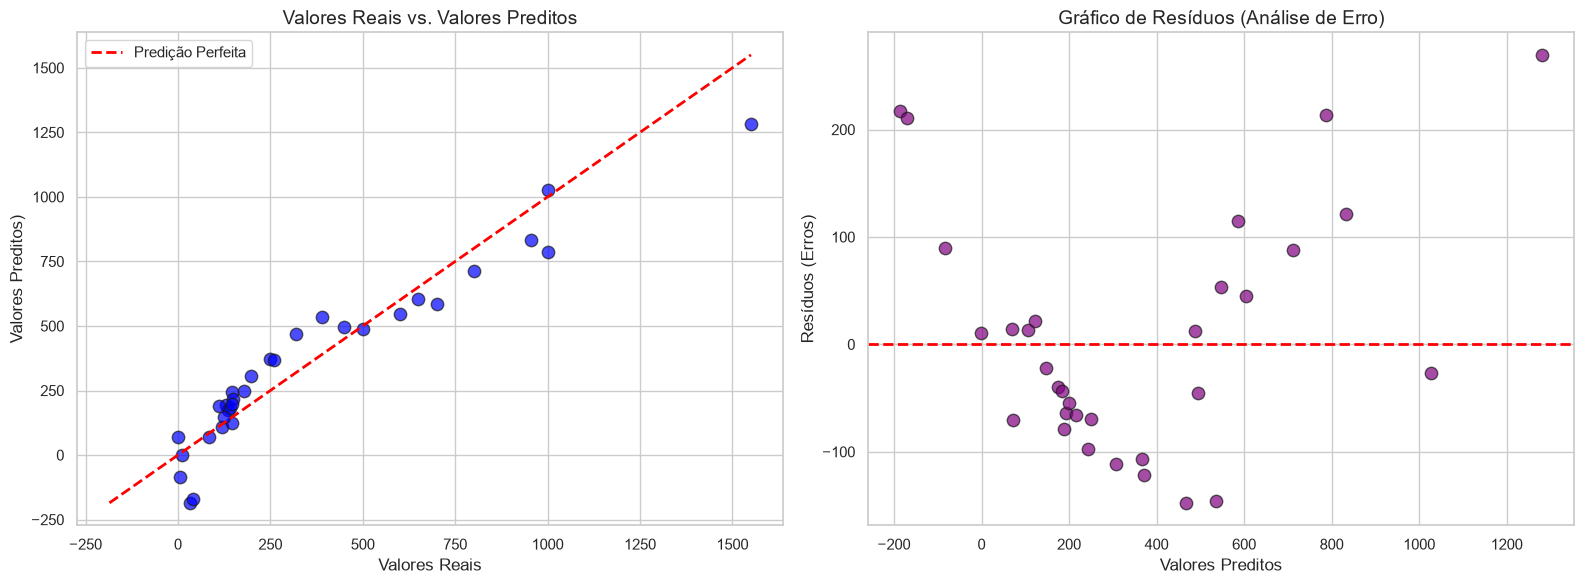


 RESULTADOS TREINAMENTO
MAE (Erro Médio Absoluto): 87.76998319758071
MSE (Erro Quadrático Médio): 12032.072402366866
RMSE (Raiz do Erro Quadrático): 109.69080363625233
R2_SCORE (Coeficiente R²): 0.9109342585807285


In [11]:
X_train_v1, X_test_v1, y_train_v1, y_test_v1 = train_test_features(dataset)

regressor.fit(X_train_v1, y_train_v1)
y_pred_v1 = regressor.predict(X_test_v1)

show_grafic_metrics(y_test_v1, y_pred_v1)